In [2]:
import csv
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Download the BBC text dataset from the online source and save it locally in the /tmp directory
!wget --no-check-certificate \
    https://storage.googleapis.com/learning-datasets/bbc-text.csv \
    -O /tmp/bbc-text.csv
print("Dataset downloaded successfully to /tmp/bbc-text.csv")

--2026-11-02 10:30:23--  https://storage.googleapis.com/learning-datasets/bbc-text.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 108.177.98.207, 74.125.195.207, 172.253.117.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|108.177.98.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5057493 (4.8M) [text/csv]
Saving to: ‘/tmp/bbc-text.csv’

/tmp/bbc-text.csv   100%[===================>]   4.82M  --.-KB/s    in 0.04s   

2026-11-02 10:30:23 (108 MB/s) - ‘/tmp/bbc-text.csv’ saved [5057493/5057493]

Dataset downloaded successfully to /tmp/bbc-text.csv


###Defining Hyperparameters and Stopwords
We set up key configuration variables for text tokenization and model architecture, along with a comprehensive list of 153 English stopwords to clean our text data.

In [3]:
# Define key hyperparameters and settings for text preprocessing and model architecture
vocab_size = 1000        # Maximum number of words to keep in the vocabulary based on frequency
embedding_dim = 16       # Dimensionality of the embedding vector for each word
max_length = 120         # Maximum allowable length for all sequences (padding/truncating limit)
trunc_type = 'post'      # Truncate sequences from the end if they exceed max_length
padding_type = 'post'    # Pad sequences with zeros from the end if they are shorter than max_length
oov_tok = "<OOV>"        # Special token to handle out-of-vocabulary words during tokenization
training_portion = .8    # Proportion of dataset to be used for training (80% train, 20% validation)

# List of common stop words to be removed from the text data (153 words total)
stopwords = [
    "a", "about", "above", "after", "again", "against", "all", "am", "an", "and",
    "any", "are", "as", "at", "be", "because", "been", "before", "being", "below",
    "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down",
    "during", "each", "few", "for", "from", "further", "had", "has", "have", "having",
    "he", "he'd", "he'll", "he's", "her", "here", "here's", "hers", "herself", "him",
    "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if",
    "in", "into", "is", "it", "it's", "its", "itself", "let's", "me", "more",
    "most", "my", "myself", "of", "off", "on", "once", "only", "or", "other",
    "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd",
    "she'll", "she's", "should", "so", "some", "such", "than", "that", "that's", "the",
    "their", "theirs", "them", "themselves", "then", "there", "there's", "these", "they",
    "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too",
    "under", "until", "up", "very", "was", "we", "we'd", "we'll", "we're", "we've",
    "were", "what", "what's", "when", "when's", "where", "where's", "which", "while",
    "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll",
    "you're", "you've", "your", "yours", "yourself", "yourselves"
]

# Print the total count of stopwords to verify the list length
print(len(stopwords))

153


###Parsing and Cleaning the Dataset
We read the CSV file line by line, separating category labels from text sentences, and strip out predefined stopwords to prepare clean text for tokenization.

In [4]:
# Initialize empty lists to store text sentences and their corresponding category labels
sentences = []
labels = []

# Open and read the downloaded CSV dataset file line by line
with open("/tmp/bbc-text.csv", 'r') as csvfile:
    reader = csv.reader(csvfile, delimiter=',')

    # Read the header row properly inside the file block
    header = next(reader)  # Skip the header row (column names)

    # Iterate through each row in the dataset
    for row in reader:
        labels.append(row[0])  # Extract and store the article category label (e.g., sport, tech)
        sentence = row[1]      # Extract the raw article text content

        # Loop through each stopword and remove it from the sentence to clean the text
        for word in stopwords:
            token = " " + word + " "
            sentence = sentence.replace(token, " ")

        sentences.append(sentence)  # Store the cleaned sentence in the list

# Print verification metrics and a sample output to ensure data is loaded and parsed correctly
print(len(labels))
print(len(sentences))
print(sentences[0])

2225
2225
tv future hands viewers home theatre systems  plasma high-definition tvs  digital video recorders moving living room  way people watch tv will radically different five years  time.  according expert panel gathered annual consumer electronics show las vegas discuss new technologies will impact one favourite pastimes. us leading trend  programmes content will delivered viewers via home networks  cable  satellite  telecoms companies  broadband service providers front rooms portable devices.  one talked-about technologies ces digital personal video recorders (dvr pvr). set-top boxes  like us s tivo uk s sky+ system  allow people record  store  play  pause forward wind tv programmes want.  essentially  technology allows much personalised tv. also built-in high-definition tv sets  big business japan us  slower take europe lack high-definition programming. not can people forward wind adverts  can also forget abiding network channel schedules  putting together a-la-carte entertainmen

##Splitting Dataset into Training and Validation Sets
We split our cleaned sentences and labels into training (80%) and validation (20%) sets using the defined training portion.

In [5]:
# Compute the training size index based on the 80% portion
train_size = int(len(sentences) * training_portion)

# Split sentences and labels into training and validation sets
train_sentences = sentences[:train_size]
train_labels = labels[:train_size]

validation_sentences = sentences[train_size:]
validation_labels = labels[train_size:]

# Print dataset split verification metrics
print(train_size)
print(len(train_sentences))
print(len(train_labels))
print(len(validation_sentences))
print(len(validation_labels))

1780
1780
1780
445
445


##Tokenizing and Padding Training Data
We tokenize the training text data into numerical sequences and apply padding so all sequences have a uniform length of 120.

In [6]:
# Initialize the Tokenizer with vocabulary size and out-of-vocabulary token
tokenizer = Tokenizer(num_words = vocab_size, oov_token=oov_tok)
tokenizer.fit_on_texts(train_sentences)
word_index = tokenizer.word_index

# Convert training sentences into numerical sequences and pad them to a fixed length
train_sequences = tokenizer.texts_to_sequences(train_sentences)
train_padded = pad_sequences(train_sequences, padding=padding_type, maxlen=max_length)

# Print sequence length verifications before and after padding
print(len(train_sequences[0]))
print(len(train_padded[0]))
print(len(train_sequences[1]))
print(len(train_padded[1]))
print(len(train_sequences[10]))
print(len(train_padded[10]))

448
120
200
120
192
120


##Tokenizing and Padding Validation Data
We transform and pad the validation sentences using the fitted tokenizer to ensure they match the training dimensions.

In [7]:
# Convert validation sentences into numerical sequences and pad them
validation_sequences = tokenizer.texts_to_sequences(validation_sentences)
validation_padded = pad_sequences(validation_sequences, padding=padding_type, maxlen=max_length)

# Print validation sequences count and padded array shape
print(len(validation_sequences))
print(validation_padded.shape)

445
(445, 120)


##Encoding Category Labels
We encode text category labels into numerical sequences using a label tokenizer and convert them into NumPy arrays for model training.

In [8]:
# Initialize a separate tokenizer for category labels
label_tokenizer = Tokenizer()
label_tokenizer.fit_on_texts(labels)

# Convert training and validation labels into numpy array sequences
training_label_seq = np.array(label_tokenizer.texts_to_sequences(train_labels))
validation_label_seq = np.array(label_tokenizer.texts_to_sequences(validation_labels))

# Print sample label sequences and their shapes
print(training_label_seq[0])
print(training_label_seq[1])
print(training_label_seq[2])
print(training_label_seq.shape)

print(validation_label_seq[0])
print(validation_label_seq[1])
print(validation_label_seq[2])
print(validation_label_seq.shape)

[4]
[2]
[1]
(1780, 1)
[5]
[4]
[3]
(445, 1)


##Building and Compiling the Model
We construct a sequential neural network consisting of an Embedding layer, Global Average Pooling, and Dense layers, then compile it using the Adam optimizer and sparse categorical crossentropy loss.

In [10]:
# Build the sequential neural network model with explicit input shape
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(vocab_size, embedding_dim, input_shape=(max_length,)), # Explicitly define input shape here
    tf.keras.layers.GlobalAveragePooling1D(),                                      # Average the word vectors across the sequence length
    tf.keras.layers.Dense(24, activation='relu'),                                  # Hidden dense layer with ReLU activation for feature extraction
    tf.keras.layers.Dense(6, activation='softmax')                                 # Output dense layer with Softmax for multi-class probability prediction
])

# Compile the model
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Display the model summary architecture and parameter counts properly
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 120, 16)        │        16,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           150 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,558 (64.68 KB)

 Trainable params: 16,558 (64.68 KB)

 Non-trainable params: 0 (0.00 B)

##Training the Model

In [11]:
# Define the total number of training epochs
num_epochs = 30

# Train the model using training data and validate it against validation data
history = model.fit(
    train_padded,
    training_label_seq,
    epochs=num_epochs,
    validation_data=(validation_padded, validation_label_seq),
    verbose=2
)

Epoch 1/30
56/56 - 5s - 95ms/step - accuracy: 0.2309 - loss: 1.7241 - val_accuracy: 0.2270 - val_loss: 1.6591
Epoch 2/30
56/56 - 0s - 5ms/step - accuracy: 0.2303 - loss: 1.6138 - val_accuracy: 0.2270 - val_loss: 1.5714
Epoch 3/30
56/56 - 0s - 5ms/step - accuracy: 0.3197 - loss: 1.5197 - val_accuracy: 0.3933 - val_loss: 1.4782
Epoch 4/30
56/56 - 0s - 5ms/step - accuracy: 0.5309 - loss: 1.4108 - val_accuracy: 0.6045 - val_loss: 1.3636
Epoch 5/30
56/56 - 0s - 5ms/step - accuracy: 0.6388 - loss: 1.2789 - val_accuracy: 0.7303 - val_loss: 1.2270
Epoch 6/30
56/56 - 0s - 6ms/step - accuracy: 0.7567 - loss: 1.1292 - val_accuracy: 0.7730 - val_loss: 1.0747
Epoch 7/30
56/56 - 0s - 5ms/step - accuracy: 0.8258 - loss: 0.9695 - val_accuracy: 0.8584 - val_loss: 0.9251
Epoch 8/30
56/56 - 0s - 5ms/step - accuracy: 0.8775 - loss: 0.8240 - val_accuracy: 0.8944 - val_loss: 0.7941
Epoch 9/30
56/56 - 0s - 5ms/step - accuracy: 0.9034 - loss: 0.6835 - val_accuracy: 0.9034 - val_loss: 0.6795
Epoch 10/30
56/56 

##Visualizing Training Results

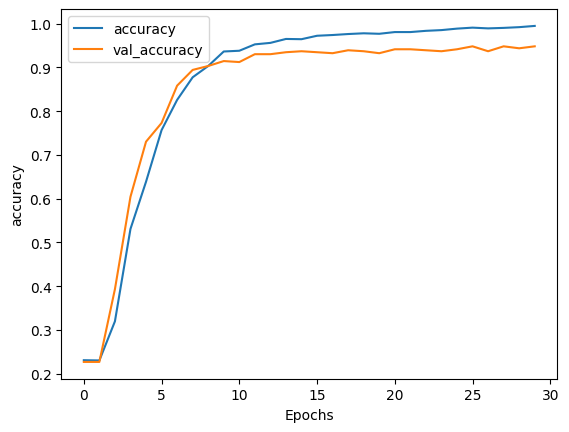

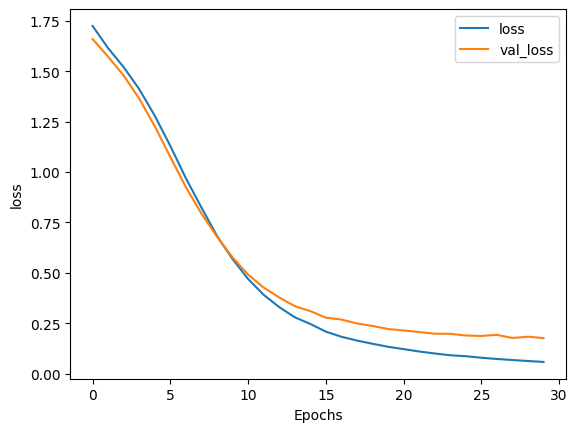

In [12]:
import matplotlib.pyplot as plt

# Define a helper function to plot training and validation metrics (accuracy/loss)
def plot_graphs(history, string):
    plt.plot(history.history[string])             # Plot training metric values
    plt.plot(history.history['val_' + string])    # Plot validation metric values
    plt.xlabel("Epochs")                          # Label the x-axis as Epochs
    plt.ylabel(string)                            # Label the y-axis with the metric name
    plt.legend([string, 'val_' + string])         # Add a legend to distinguish training vs validation
    plt.show()                                    # Display the plot

# Plot training and validation accuracy over epochs
plot_graphs(history, "accuracy")

# Plot training and validation loss over epochs
plot_graphs(history, "loss")